In [1]:
import numpy as np
import matplotlib.pyplot as plt
from classy import Class
from getdist.mcsamples import loadMCSamples

In [2]:


# 1. LOAD CHAINS
chains = loadMCSamples("../chains_mavan_desy5_final/pngb_mavan_desy5_final")

# 2. SETTINGS
nsamples = 200   # Start small to test if it works, then increase to 200+
z_grid = np.linspace(0, 10, 200)
all_meff = []

# Use weights for statistical correctness
weights = chains.weights
indices = np.random.choice(len(weights), size=nsamples,replace=False, p=weights/weights.sum())

print(f"Starting reconstruction for {nsamples} samples...")

# 3. LOOP
for k, idx in enumerate(indices):
    cosmo = Class()
    try:
        # Extract parameters
        p = lambda name: chains.samples[idx, chains.index[name]]
        
        params = {
            'omega_b': p('omega_b'),
            'omega_cdm': p('omega_cdm'),
            'H0': p('H0'),
            'A_s': p('A_s'),
            'n_s': p('n_s'),
            'N_ur': 2.0308,
            'N_ncdm': 1,
            'm_ncdm': 0.06,
            'T_ncdm': 0.71611,
            'deg_ncdm': 1,
            'beta_ncdm': p('beta_ncdm'),
            'scf_parameters': f"{p('f_pngb')}, -7, {p('phi_ini')}, 0.0",
            'Omega_fld': 0.0,
            'Omega_scf': -1,
            'Omega_Lambda': 0.0,
            'mavan_ncdm': 'True',
            'gauge': 'synchronous',
            'ncdm_fluid_approximation': 2,
            'non_linear': 'halofit',
            'nonlinear_min_k_max': 5,          
            'attractor_ic_scf': 'no',
            'scf_tuning_index': 1,
            'output': 'mPk',
            'P_k_max_1/Mpc': 1.0,
        }

        cosmo.set(params)
        cosmo.compute()

        bg = cosmo.get_background()
        
         # =========================
        # Background quantities
        # =========================
        z_bg = bg['z']
        phi_scf = bg['phi_scf']
        
        # sort in ascending z
        order = np.argsort(z_bg)
        
        z_sorted = z_bg[order]
        phi_sorted = phi_scf[order]
        
        beta_val = p('beta_ncdm')
        
        # present-day neutrino mass
        m0 = 0.06
        
        # phi today
        phi0 = phi_sorted[0]
        
        # effective neutrino mass
        m_eff = m0 * np.exp(
            beta_val * (phi_sorted - phi0)
        )
        
        # interpolate
        m_interp = np.interp(
            z_grid,
            z_sorted,
            m_eff
        )
        
        all_meff.append(m_interp)
        print(f"Success: {k+1}/{nsamples}", end="\r")

    except Exception as e:
        print(f"\nError at index {idx}: {e}")
    finally:
        cosmo.struct_cleanup()
        cosmo.empty()

# 4. STATISTICS & PLOTTING
if len(all_meff) == 0:
    print("Error: No successful CLASS runs. Check your parameter names and CLASS version.")
else:
    all_meff = np.array(all_meff)
    
    median = np.percentile(all_meff, 50, axis=0)
    low68, high68 = np.percentile(all_meff, [16, 84], axis=0)
    low95, high95 = np.percentile(all_meff, [2.5, 97.5], axis=0)


../chains_mavan_desy5_final/pngb_mavan_desy5_final.1.txt
../chains_mavan_desy5_final/pngb_mavan_desy5_final.2.txt
../chains_mavan_desy5_final/pngb_mavan_desy5_final.3.txt
../chains_mavan_desy5_final/pngb_mavan_desy5_final.4.txt
../chains_mavan_desy5_final/pngb_mavan_desy5_final.5.txt
../chains_mavan_desy5_final/pngb_mavan_desy5_final.6.txt
../chains_mavan_desy5_final/pngb_mavan_desy5_final.7.txt
../chains_mavan_desy5_final/pngb_mavan_desy5_final.8.txt
Removed no burn in
Starting reconstruction for 200 samples...
Success: 123/200
Error at index 179488: 

Error in Class: background_init(L:882) :condition (pba->shooting_failed == _TRUE_) is true; Shooting failed, try optimising input_get_guess(). Error message:

input_shooting(L:776) :error in fzero_Newton(input_try_unknown_parameters, x_inout, dxdF, ((mavan_enabled_for_shooting == _TRUE_) && (beta_mavan_for_shooting != 0.)) ? 0.5 : 0., unknown_parameters_size, ppr->tol_shooting_deltax, ppr->tol_shooting_deltaF, &fzw, &fevals, errmsg);
=>

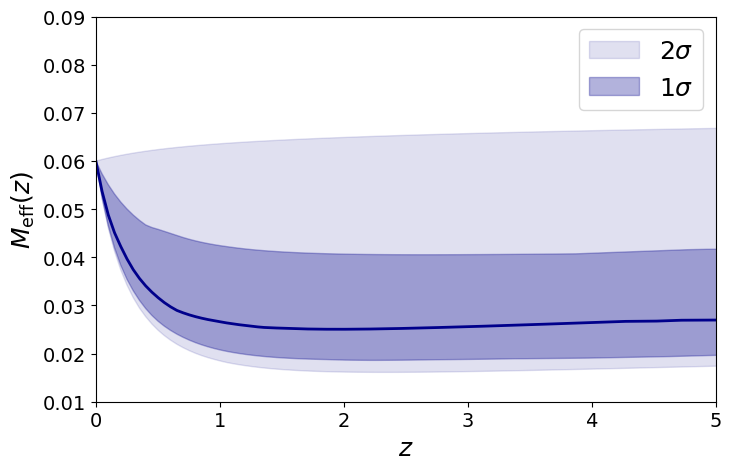

In [5]:
plt.figure(figsize=(8, 5))

plt.fill_between(
    z_grid,
    low95,
    high95,
    alpha=0.12,
    color='darkblue',
    label=r'$2\sigma$'
)

plt.fill_between(
    z_grid,
    low68,
    high68,
    alpha=0.30,
    color='darkblue',
    label=r'$1\sigma$'
)

plt.plot(
    z_grid,
    median,
    color='darkblue',
    lw=2,
)

plt.xlabel(r'$z$', fontsize=18)
plt.ylabel(r'$M_{\rm eff}(z)$', fontsize=18)

plt.xlim(0, 5)
plt.ylim(0.01, 0.09)

plt.xticks(fontsize=14)
plt.yticks(fontsize=14)

plt.legend(fontsize=18)

plt.savefig('meff_data.pdf', bbox_inches='tight')
plt.show()